## Fetch and Display NYSE Stock Data

### yfinance module
nyse 종목

In [1]:
# _tsa_00.py
# nyse stock

# 코랩 추가.
!pip install yfinance

import os
import numpy as np                          # numpy 라이브러리 전체.
import pandas as pd                         # pandas 라이브러리 전체, 시계열(기본) 여기 있네.
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import yfinance as yf                       ## NYSE 데이터 모듈
from scipy import stats, optimize, linalg   # scipy 라이브러리 하부 모듈.
from statsmodels.tsa import stattools       # time series analysis
from statsmodels.tsa.arima.model import ARIMA # 이거 가능하다 이거지. 이거 대문자네. 꼭.
from statsmodels.tsa.ar_model import AutoReg


### Tickers and close prices

In [2]:
# import pandas as pd
# import yfinance as yf

# 종목 리스트 한 번에 가져오는 아이디어.
# 1. 나스닥 주요 상위 종목 티커 리스트
tickers = ["AAPL", "MSFT", "NVDA", "AMZN", "META",
           "GOOGL", "TSLA", "AVGO", "COST", "NFLX",
           "SKHY", "MU", "AMD", "ASML", "TSM",
           "INTC"]
stock_data = []

# 2. 각 종목의 세부 정보 가져오기
for tckr in tickers:
    stock = yf.Ticker(tckr)
    info = stock.info

    stock_data.append({
        "티커": tckr,
        "기업명": info.get("longName", "N/A"),
        "섹터": info.get("sector", "N/A"),
        "현재가($)": info.get("currentPrice", "N/A"),
        "시가총액($)": f"{info.get('marketCap', 0):,}"
    })

# 3. 데이터프레임 변환 및 출력
df_tckr = pd.DataFrame(stock_data)
print(df_tckr)

# 티커에 대한 가격, 볼륨 데이터, k 년 자료 가져오기
df_dat = yf.download(tickers, period='1y', auto_adjust=True)
df_dat.info()   # ticker마다 close, open, volume 등

# 다운 자료 중 종가 추출
df_dat_cls = df_dat['Close'].copy()
df_dat_cls
returns = np.log(df_dat_cls / df_dat_cls.shift(1))
returns

[                       0%                       ]

[******                12%                       ]  2 of 16 completed

       티커                                                기업명  \
0    AAPL                                         Apple Inc.   
1    MSFT                              Microsoft Corporation   
2    NVDA                                 NVIDIA Corporation   
3    AMZN                                   Amazon.com, Inc.   
4    META                               Meta Platforms, Inc.   
5   GOOGL                                      Alphabet Inc.   
6    TSLA                                        Tesla, Inc.   
7    AVGO                                      Broadcom Inc.   
8    COST                       Costco Wholesale Corporation   
9    NFLX                                      Netflix, Inc.   
10   SKHY                                      SK hynix Inc.   
11     MU                            Micron Technology, Inc.   
12    AMD                       Advanced Micro Devices, Inc.   
13   ASML                                  ASML Holding N.V.   
14    TSM  Taiwan Semiconductor Manufact

[*********             19%                       ]  3 of 16 completed

[************          25%                       ]  4 of 16 completed

...

[**********************88%*****************      ]  14 of 16 completed

[**********************94%********************   ]  15 of 16 completed

[*********************100%***********************]  16 of 16 completed

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 251 entries, 2025-10-17 to 2026-10-16
Data columns (total 80 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (Close, AAPL)    251 non-null    float64
 1   (Close, AMD)     251 non-null    float64
 2   (Close, AMZN)    251 non-null    float64
 3   (Close, ASML)    251 non-null    float64
 4   (Close, AVGO)    251 non-null    float64
 5   (Close, COST)    251 non-null    float64
 6   (Close, GOOGL)   251 non-null    float64
 7   (Close, INTC)    251 non-null    float64
 8   (Close, META)    251 non-null    float64
 9   (Close, MSFT)    251 non-null    float64
 10  (Close, MU)      251 non-null    float64
 11  (Close, NFLX)    251 non-null    float64
 12  (Close, NVDA)    251 non-null    float64
 13  (Close, SKHY)    70 non-null     float64
 14  (Close, TSLA)    251 non-null    float64
 15  (Close, TSM)     251 non-null    float64
 16  (High, AAPL)     251 non-null    float64
 1

Ticker,AAPL,AMD,AMZN,ASML,AVGO,COST,GOOGL,INTC,META,MSFT,MU,NFLX,NVDA,SKHY,TSLA,TSM
Date,,,,,,,,,,,,,,,,
2025-10-17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-10-20,0.038681,0.031588,0.016018,0.012436,-0.000258,-0.000235,0.012749,0.029026,0.021048,0.006231,0.021460,0.032161,-0.003171,NaN,0.018315,0.008840
2025-10-21,0.002019,-0.010573,0.025314,-0.016574,-0.019021,0.001484,-0.024024,0.000525,0.001501,0.001682,-0.021905,0.002250,-0.008136,NaN,-0.010854,-0.010773
2025-10-22,-0.016577,-0.033318,-0.018547,-0.013209,-0.006911,0.007629,0.004899,-0.031986,0.000191,0.005548,-0.019064,-0.106117,-0.004869,NaN,-0.008235,-0.019301
2025-10-23,0.004363,0.020464,0.014304,0.024259,0.011657,-0.002788,0.005508,0.033034,0.000804,0.000038,0.040679,-0.002493,0.010374,NaN,0.022547,0.006384
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-12,0.012780,-0.023056,-0.011112,-0.017051,-0.019016,0.013135,0.003010,-0.032519,0.033240,0.011299,-0.039608,0.004400,-0.012994,-0.041061,-0.012278,-0.019964
2026-10-13,0.000879,0.018821,-0.003667,-0.018732,0.007247,-0.005026,0.003001,0.014303,0.025960,0.004241,-0.036920,-0.002127,0.009674,-0.032387,-0.007434,0.001731
2026-10-14,0.004940,-0.059030,-0.017556,-0.040246,-0.031443,0.028267,-0.017508,-0.046691,-0.033282,-0.018123,-0.041684,0.001560,-0.032104,-0.062461,-0.021741,-0.034559


### subplots, line chart, prices, returns

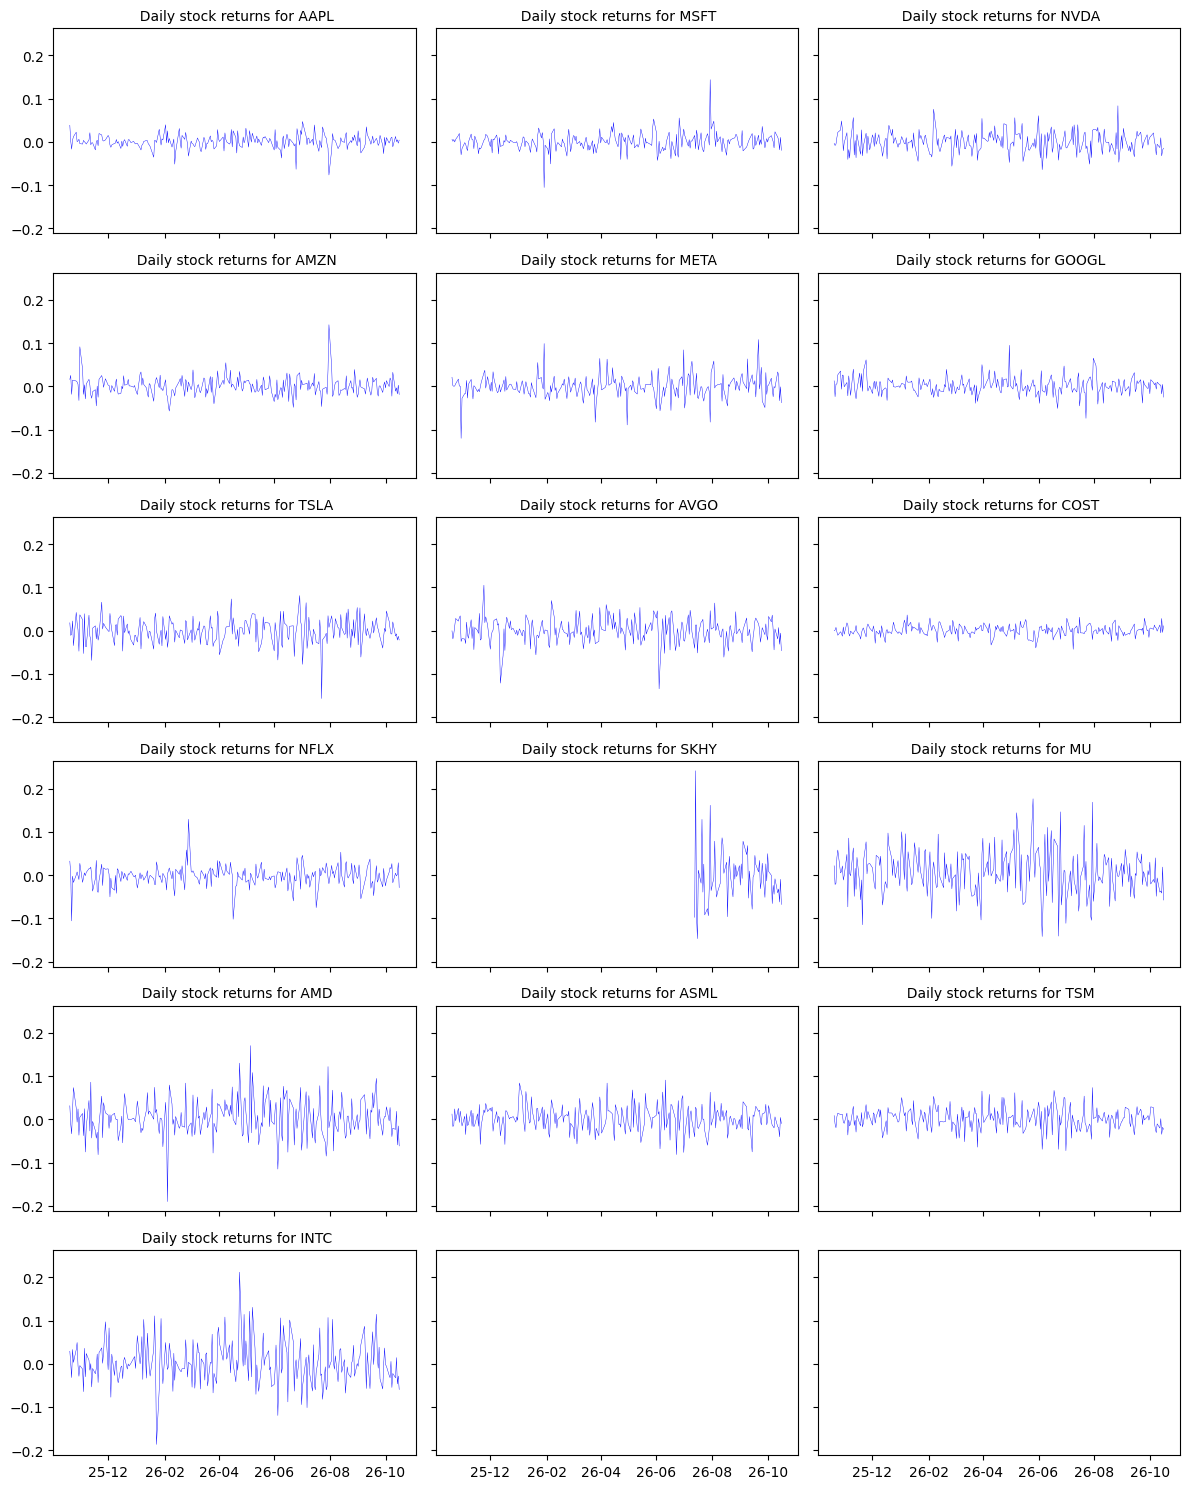

In [3]:
# NYSE daily stock prices and trading volumes
# 변수로 받는 방법.
yymmdd = df_dat.index   # 자료를 불러올 때, 자동으로 기준 인덱스로 설정된다고 함.
yymmdd = pd.to_datetime( yymmdd )

n_plot = len(tickers)
sub_c = 3
sub_r = int(np.ceil(n_plot/sub_c))

fig, axes = plt.subplots(sub_r, sub_c,
                         figsize=(sub_c*4, sub_r*2.5),
                         sharex=True,
                         sharey=True
                         )

for ax, ticker in zip(axes.flat, tickers) :
  ax.plot(yymmdd,
          returns[ticker],
          #df_dat_cls[ticker].pct_change(fill_method=None),
          color='blue',
          linewidth=0.3
          )  # 여기 ticker는 이미 "AAPL"처럼 인식, 앞에서.
  ax.set_title(f"  Daily stock returns for {ticker} ", fontsize=10)
  ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
  ax.xaxis.set_major_formatter(mdates.DateFormatter('%y-%m'))
plt.tight_layout()
plt.show()

### subplots, histograms, daily returns

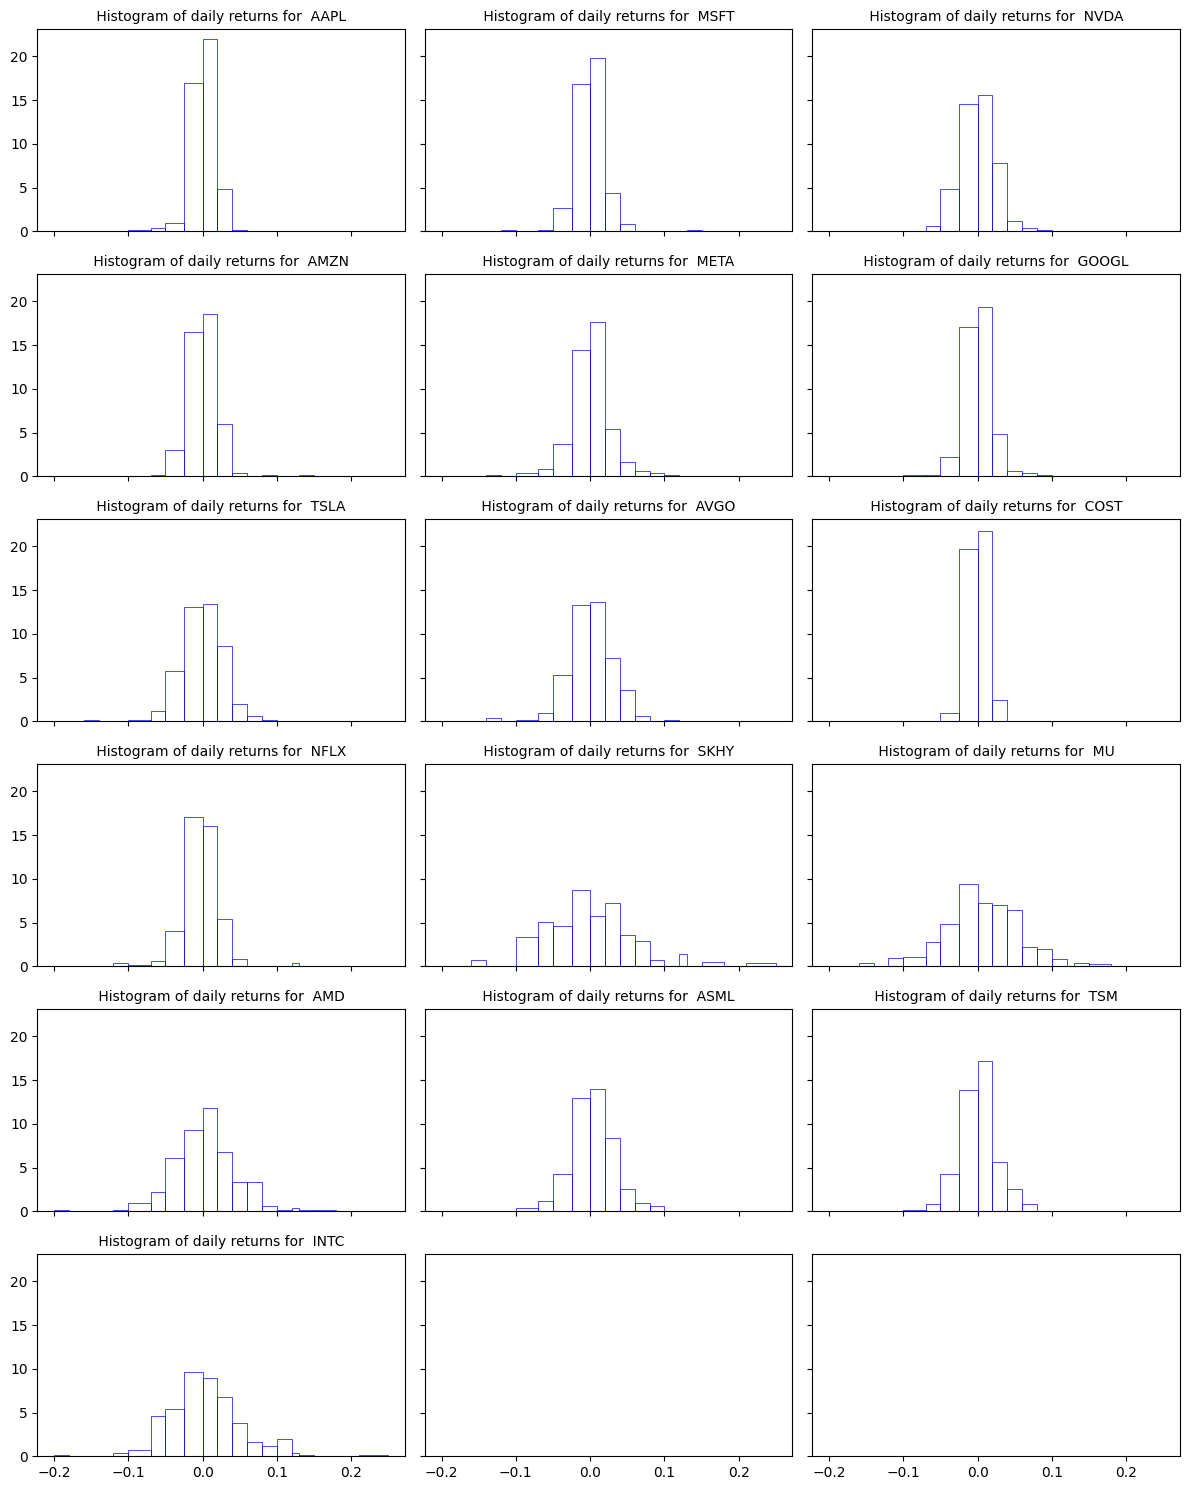

In [4]:
# NYSE daily stock prices and trading volumes
# 변수로 받는 방법.
#yymmdd = df_dat.index   # 자료를 불러올 때, 자동으로 기준 인덱스로 설정된다고 함.
#yymmdd = pd.to_datetime( yymmdd )

n_plot = len(tickers)
sub_c = 3
sub_r = int(np.ceil(n_plot/sub_c))

b_class = [-0.2, -0.18, -0.16, -0.14, -0.12, -0.1, -0.07,-0.05, -0.025,
           0.0,
           0.02, 0.04, 0.06, 0.08, 0.1, 0.12, 0.13, 0.15, 0.18, 0.21, 0.25]

fig, axes = plt.subplots(sub_r, sub_c,
                         figsize=(sub_c*4, sub_r*2.5),
                         sharex=True,
                         sharey=True
                         )
for ax, ticker in zip(axes.flat, tickers) :
  ax.hist(returns[ticker],
          #df_dat_cls[ticker].pct_change(fill_method=None), # 여기 ticker는 이미 "AAPL"처럼 인식, 앞에서.
          color='blue',
          linewidth=0.5,
          bins = b_class,       # 11처럼 갯수로 지정, 혹은 계급 구간 제시,
          facecolor='None',
          edgecolor='blue',
          density=True
          )
  ax.set_title(f" Histogram of daily returns for  {ticker} ", fontsize=10)
plt.tight_layout()
plt.show()

### two tickers, prices
뭔가 간단하게

In [5]:
# NYSE daily stock prices and trading volumes
# 변수로 받는 방법.
yymmdd = df_dat.index   # 자료를 불러올 때, 자동으로 기준 인덱스로 설정된다고 함.
yymmdd = pd.to_datetime( yymmdd )

tic_1 = 'NFLX'
tic_2 = 'GOOGL'
stck_prc_1= df_dat_cls[tic_1]
stck_prc_2 = df_dat_cls[tic_2]


#### daily stock returns

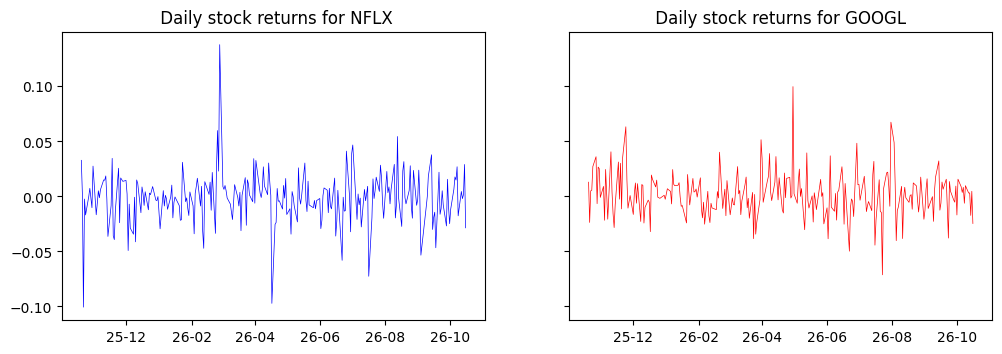

In [6]:
# 나란히 차트 2개. 1행, 2열.
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16*0.75, 10*0.75/2), sharex=True, sharey=True )
axes[0].plot(yymmdd, stck_prc_1.pct_change(fill_method=None), color='blue', linewidth=0.5)
axes[1].plot(yymmdd, stck_prc_2.pct_change(fill_method=None), color='red', linewidth=0.5)

axes[0].set_title(f" Daily stock returns for {tic_1}")
axes[1].set_title(f" Daily stock returns for {tic_2} ")
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%y-%m'))


#### distibutions in one chart

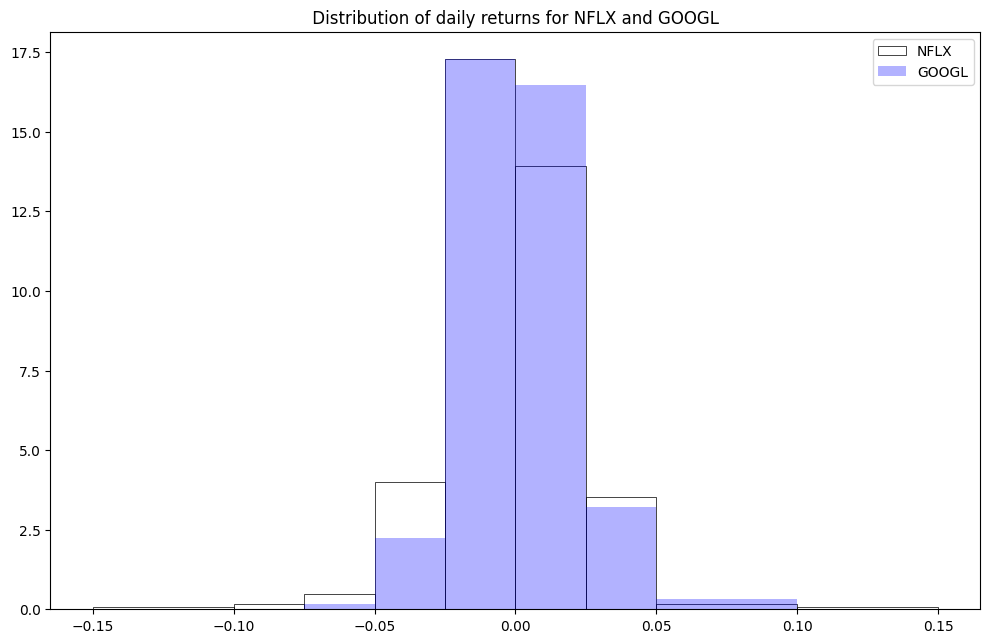

In [7]:
# 차트 여러 개, 화면 1개.
b_class = [-0.15, -0.1, -0.075, -0.05, -0.025, 0, 0.025, 0.05, 0.1, 0.15 ]
plt.figure(figsize=(12, 7.5))
plt.hist(stck_prc_1.pct_change(fill_method=None),
         color='blue',
         linewidth=0.51,
         bins = b_class, # 11,
         facecolor='None',
         edgecolor='black',
         density=True,
         label = f"{tic_1}"
         )
plt.hist(stck_prc_2.pct_change(fill_method=None),
         color='blue',
         linewidth=1,
         bins = b_class, # 11,
         facecolor='blue',
         edgecolor='None',
         density=True,
         #linestyle='--'
         label = f"{tic_2}",
         alpha = 0.3
         )
plt.title(f" Distribution of daily returns for {tic_1} and {tic_2} ")
plt.legend()
plt.show()